In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
from sklearn.preprocessing import  OneHotEncoder, LabelEncoder
from sklearn.compose import make_column_transformer, make_column_selector
from tqdm import tqdm
from xgboost import XGBRegressor


In [7]:
housing=pd.read_csv("Housing.csv")
print("First five row")
print(housing.head())
print("\nShape of the Housing",housing.shape)
print("\nData type of the Housing\n",housing.dtypes)
print("\nMissing value counts",housing.isnull().sum())

First five row
     price  lotsize  bedrooms  bathrms  stories driveway recroom fullbase  \
0  42000.0     5850         3        1        2      yes      no      yes   
1  38500.0     4000         2        1        1      yes      no       no   
2  49500.0     3060         3        1        1      yes      no       no   
3  60500.0     6650         3        1        2      yes     yes       no   
4  61000.0     6360         2        1        1      yes      no       no   

  gashw airco  garagepl prefarea  
0    no    no         1       no  
1    no    no         0       no  
2    no    no         0       no  
3    no    no         0       no  
4    no    no         0       no  

Shape of the Housing (546, 12)

Data type of the Housing
 price       float64
lotsize       int64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl      int64
prefarea        str
dtype: object

In [8]:
X=housing.drop(columns='price')
y=housing['price']

In [9]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=25)

In [10]:
preprocess = make_column_transformer(
    (OneHotEncoder(drop="first", sparse_output=False), make_column_selector(dtype_include=['object', 'category'])),
    remainder="passthrough"
)

In [11]:
X_train_trns = preprocess.fit_transform(X_train)
X_test_trns = preprocess.transform(X_test)

features_names=preprocess.get_feature_names_out()
print(list(features_names))

['onehotencoder__driveway_yes', 'onehotencoder__recroom_yes', 'onehotencoder__fullbase_yes', 'onehotencoder__gashw_yes', 'onehotencoder__airco_yes', 'onehotencoder__prefarea_yes', 'remainder__lotsize', 'remainder__bedrooms', 'remainder__bathrms', 'remainder__stories', 'remainder__garagepl']


In [12]:
from sklearn.tree import DecisionTreeRegressor,plot_tree

dtc_house = DecisionTreeRegressor(random_state=25, max_depth=2)
dtc_house.fit(X_train_trns, y_train)



,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",25
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

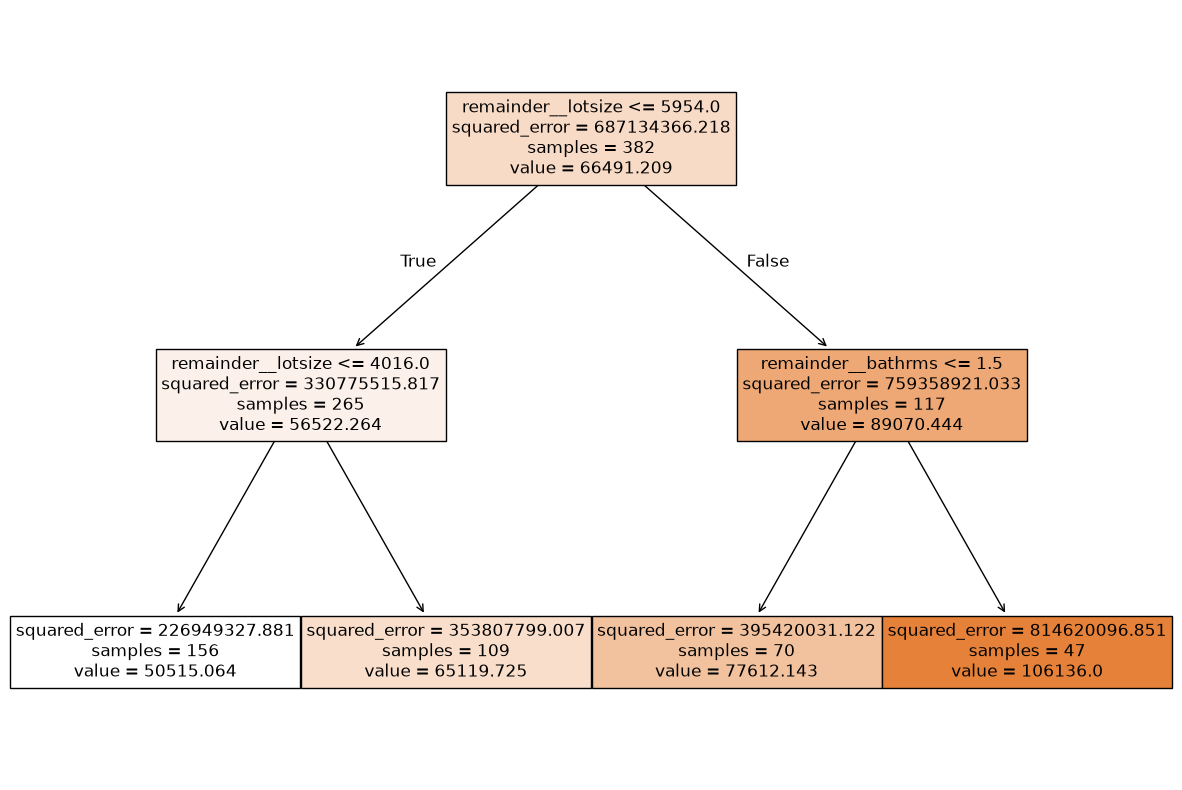

In [13]:
plt.figure(figsize=(15,10))
plot_tree(dtc_house, feature_names=list(features_names), 
           filled=True,fontsize=12)
plt.show() 

In [14]:
from sklearn.metrics import r2_score
y_pred=dtc_house.predict(X_test_trns)
print(r2_score(y_test,y_pred))

0.3865878044059061


In [15]:
mean_y_train=y_train.mean()
print("Mean Training set price",mean_y_train)

Mean Training set price 66491.20942408378


The mean training-set house price is exactly equal to the value displayed at the root node of the decision tree. In a regression tree, before any splits are made, the predicted output for the root node is simply the overall average (mean) of the target variable (y) in the training set

In [16]:
mean_sq_dev=np.mean((y_train-mean_y_train)**2)
print("Mean square deviation of the traning set price",mean_sq_dev)

Mean square deviation of the traning set price 687134366.2179216


The mean squared deviation of training prices from their mean matches the root node's squared_error (or mse) impurity value exactly. In decision tree regression, the default impurity criterion is Mean Squared Error (MSE), which measures the sample variance of the target values within that node.

In [17]:
subset_above_threshold=y_train[X_train['lotsize']>5954]
subset_below_threshold=y_train[X_train['lotsize']<= 5954]

print(f"Mean price (lotsize > 5954): {subset_above_threshold.mean():.4f}")
print(f"Mean price (lotsize <= 5954): {subset_below_threshold.mean():.4f}")

Mean price (lotsize > 5954): 89070.4444
Mean price (lotsize <= 5954): 56522.2642


In [18]:
depths = [2, 3, 4, 5, 8, None]
leaves = [1, 5, 10, 20, 50]
splits = [2, 5, 10, 20, 50]
scores = []
for d in depths:
    for l in leaves:
        for s in splits:
            dtc = DecisionTreeRegressor(random_state=25, max_depth=d,
                                         min_samples_leaf=l, min_samples_split=s)
            dtc.fit(X_train_trns, y_train)
            y_pred = dtc.predict(X_test_trns)
            scores.append([d,l,s, r2_score(y_test, y_pred )] )
df_scores_house = pd.DataFrame( scores, columns=['Depth','Minimum Samples per Leaf','Minimum Samples to Split','R² Score'] )


In [19]:
sorted_df_house=df_scores_house.sort_values( 'R² Score', ascending=False )
print(sorted_df_house)

     Depth  Minimum Samples per Leaf  Minimum Samples to Split  R² Score
103    8.0                         1                        20  0.520188
108    8.0                         5                        20  0.517948
128    NaN                         1                        20  0.516177
78     5.0                         1                        20  0.514985
133    NaN                         5                        20  0.513971
..     ...                       ...                       ...       ...
127    NaN                         1                        10  0.344446
101    8.0                         1                         5  0.339508
126    NaN                         1                         5  0.286563
100    8.0                         1                         2  0.282023
125    NaN                         1                         2  0.091176

[150 rows x 4 columns]


In [20]:
top_5_r2_score=df_scores_house.sort_values( 'R² Score', ascending=False ).head(5)
print("Top 5 R2 score\n",top_5_r2_score)

Top 5 R2 score
      Depth  Minimum Samples per Leaf  Minimum Samples to Split  R² Score
103    8.0                         1                        20  0.520188
108    8.0                         5                        20  0.517948
128    NaN                         1                        20  0.516177
78     5.0                         1                        20  0.514985
133    NaN                         5                        20  0.513971


In [21]:
highest_scoring_configuration=df_scores_house.sort_values( 'R² Score', ascending=False ).iloc[0]
print("Highest Score Configuration\n",
      highest_scoring_configuration)

Highest Score Configuration
 Depth                        8.000000
Minimum Samples per Leaf     1.000000
Minimum Samples to Split    20.000000
R² Score                     0.520188
Name: 103, dtype: float64


Sorted Feature Importances:
                        Feature  Importance
6            remainder__lotsize    0.569796
8            remainder__bathrms    0.219284
9            remainder__stories    0.042706
5   onehotencoder__prefarea_yes    0.033978
3      onehotencoder__gashw_yes    0.032746
10          remainder__garagepl    0.030994
2   onehotencoder__fullbase_yes    0.022467
7           remainder__bedrooms    0.021059
4      onehotencoder__airco_yes    0.018979
0   onehotencoder__driveway_yes    0.004319
1    onehotencoder__recroom_yes    0.003671


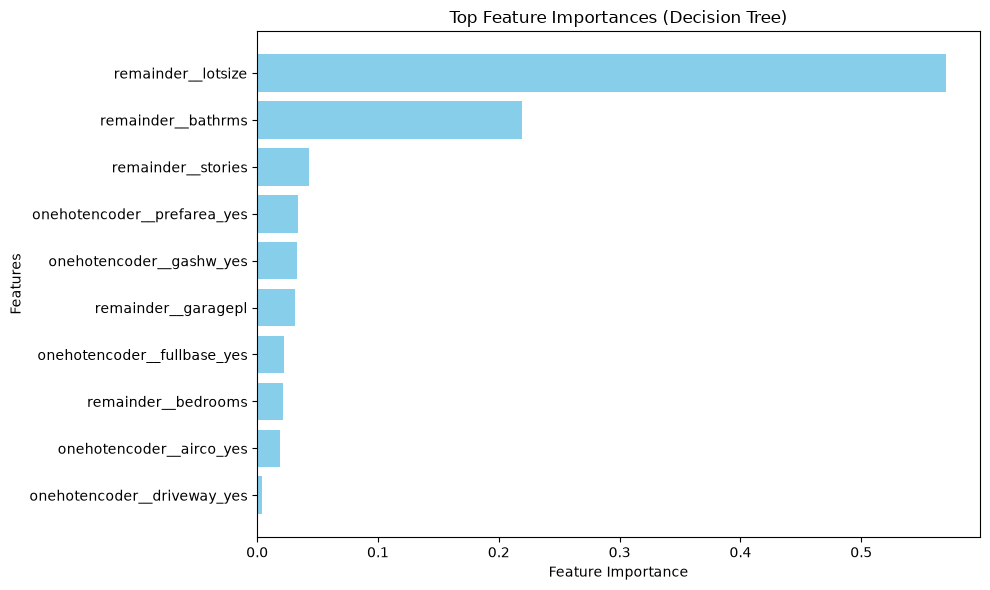

In [22]:
best_tree=DecisionTreeRegressor(
    max_depth=8,             
    min_samples_leaf=1,      
    min_samples_split=20,     
    random_state=25
)

best_tree.fit(X_train_trns,y_train)

feature_importances=pd.DataFrame({
    'Feature':preprocess.get_feature_names_out(),
    'Importance':best_tree.feature_importances_
}).sort_values(by='Importance',ascending=False)

print("Sorted Feature Importances:")
print(feature_importances)

plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'][:10][::-1], feature_importances['Importance'][:10][::-1], color='skyblue')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top Feature Importances (Decision Tree)')
plt.tight_layout()
plt.show()

In [23]:
print(feature_importances.head(3))

              Feature  Importance
6  remainder__lotsize    0.569796
8  remainder__bathrms    0.219284
9  remainder__stories    0.042706


In [24]:
bathrooms_mean_price = housing.groupby('bathrms')['price'].mean()
print(bathrooms_mean_price)



bathrms
1     60153.233831
2     88702.947368
3    104030.000000
4    175000.000000
Name: price, dtype: float64


In [25]:
concrete=pd.read_csv("Concrete_Data.csv")
X=concrete.drop(columns="Strength")
y=concrete['Strength']

In [26]:
print(X.dtypes)

Cement              float64
Blast               float64
Fly                 float64
Water               float64
Superplasticizer    float64
Coarse              float64
Fine                float64
Age                   int64
dtype: object


Don't need to use the one hot encoding  because all feature data types are numeric

In [27]:
X_train_c,X_test_c,y_train_c,y_test_c=train_test_split(X,y,train_size=0.3,random_state=25)

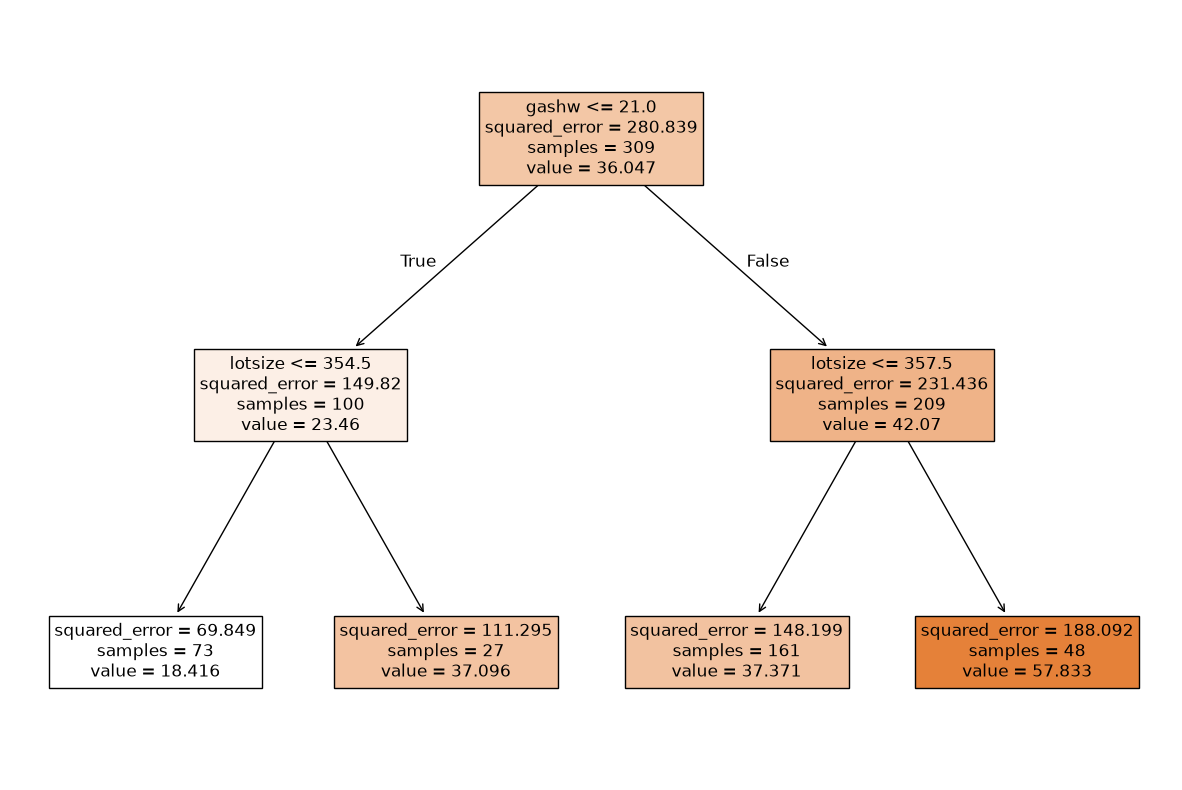

Concrete Baseline Test R² Score: 0.4615


In [28]:
dtc_concrete=DecisionTreeRegressor(max_depth=2,random_state=25,)
dtc_concrete.fit(X_train_c,y_train_c)
plt.figure(figsize=(15,10))
plot_tree(dtc_concrete, feature_names=list(X_train.columns), 
           filled=True,fontsize=12)
plt.show() 

y_pred_c=dtc_concrete.predict(X_test_c)
print(f"Concrete Baseline Test R² Score: {r2_score(y_test_c, y_pred_c):.4f}")



In [29]:
scores_concrete = []
for d in depths:
    for l in leaves:
        for s in splits:
            dtc = DecisionTreeRegressor(random_state=25, max_depth=d,
                                         min_samples_leaf=l, min_samples_split=s)
            dtc.fit(X_train_c, y_train_c)
            y_pred = dtc.predict(X_test_c)
            scores_concrete.append([d,l,s, r2_score(y_test_c, y_pred_c )] )
df_concrete_scores = pd.DataFrame( scores, columns=['Depth','Minimum Samples per Leaf','Minimum Samples to Split','R² Score'] )

df_concrete_sorted = df_concrete_scores.sort_values(
    by='R² Score', ascending=False
)

print('Top 5 Configurations for Concrete Dataset:')
print(df_concrete_sorted.head(5))




Top 5 Configurations for Concrete Dataset:
     Depth  Minimum Samples per Leaf  Minimum Samples to Split  R² Score
103    8.0                         1                        20  0.520188
108    8.0                         5                        20  0.517948
128    NaN                         1                        20  0.516177
78     5.0                         1                        20  0.514985
133    NaN                         5                        20  0.513971


Sorted Concrete Feature Importances:


,Feature,Importance
0,Cement,0.433709
7,Age,0.335259
3,Water,0.101189
1,Blast,0.057528
5,Coarse,0.039486
6,Fine,0.016917
4,Superplasticizer,0.012916
2,Fly,0.002997


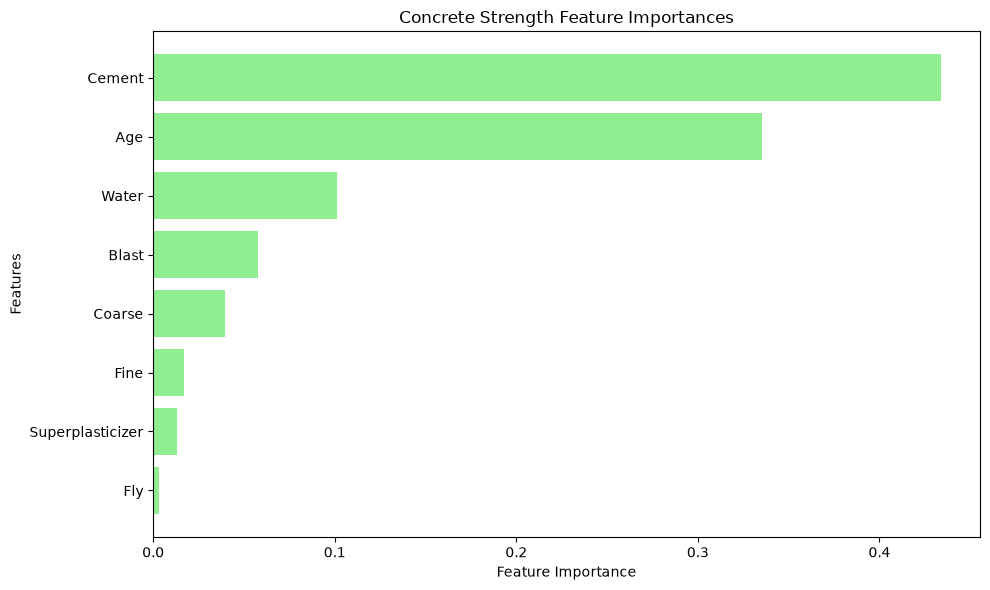

In [30]:
best_concrete_config=df_concrete_sorted.iloc[0]

best_concrete_tree=DecisionTreeRegressor(random_state=25,max_depth=int(best_concrete_config['Depth']),min_samples_leaf=int(best_concrete_config['Minimum Samples per Leaf']),min_samples_split=int(best_concrete_config['Minimum Samples to Split']))
best_concrete_tree.fit(X_train_c,y_train_c)

concrete_importances=pd.DataFrame({
    'Feature':X_train_c.columns,
    'Importance':best_concrete_tree.feature_importances_
}).sort_values(by='Importance',ascending=False)

print("Sorted Concrete Feature Importances:")
display(concrete_importances)


plt.figure(figsize=(10, 6))
plt.barh(concrete_importances['Feature'][::-1], concrete_importances['Importance'][::-1], color='lightgreen')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Concrete Strength Feature Importances')
plt.tight_layout()
plt.show()

In [31]:
housing_initial_r2=r2_score(y_test,dtc_house.predict(X_test_trns))

housing_best_row = df_scores_house.sort_values('R² Score', ascending=False).iloc[0]
housing_best_r2 = housing_best_row['R² Score']
housing_best_depth = housing_best_row['Depth']
housing_best_leaf = housing_best_row['Minimum Samples per Leaf']
housing_best_split = housing_best_row['Minimum Samples to Split']

concrete_initial_r2 = r2_score(y_test_c, dtc_concrete.predict(X_test_c))


concrete_best_row = df_concrete_scores.sort_values('R² Score', ascending=False).iloc[0]
concrete_best_r2 = concrete_best_row['R² Score']
concrete_best_depth = concrete_best_row['Depth']
concrete_best_leaf = concrete_best_row['Minimum Samples per Leaf']
concrete_best_split = concrete_best_row['Minimum Samples to Split']

comparison_data = [
    [
        'Housing', 
        housing_initial_r2, 
        housing_best_r2, 
        housing_best_depth, 
        housing_best_leaf, 
        housing_best_split
    ],
    [
        'Concrete', 
        concrete_initial_r2, 
        concrete_best_r2, 
        concrete_best_depth, 
        concrete_best_leaf, 
        concrete_best_split
    ]
]

df_comparison = pd.DataFrame(
    comparison_data, 
    columns=[
        'Dataset', 
        'Initial Tree (max_depth=2) R²', 
        'Highest Observed Test R²', 
        'Selected Depth', 
        'Selected Leaf Setting', 
        'Selected Split Setting'
    ]
)
print(df_comparison)


    Dataset  Initial Tree (max_depth=2) R²  Highest Observed Test R²  \
0   Housing                       0.386588                  0.520188   
1  Concrete                       0.461519                  0.520188   

   Selected Depth  Selected Leaf Setting  Selected Split Setting  
0             8.0                    1.0                    20.0  
1             8.0                    1.0                    20.0  
